In [ ]:
                                          --------------------------------------------------------------------
                                           Olist E-Commerce Delivery Delay and Customer Satisfaction Analysis
                                          --------------------------------------------------------------------
# Project Summary
This project focuses on analyzing delivery performance in the Olist e-commerce dataset. The main objective is to identify late delivery patterns,
understand factors associated with delivery delays, evaluate customer satisfaction and provide business insights.

**Tools & Technologies:
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

# Project Objectives
- Analyze overall delivery performance.
- Identify late and on-time orders.
- Examine delivery delays across customer states and sellers.
- Analyze the relationship between delivery performance and customer satisfaction.
- Identify patterns based on freight value and purchase month.

# Dataset Overview
- Total delivered orders analyzed: 96,470
- Main analysis: Delivery performance and late delivery patterns.

# Key Business Findings
1. Overall late delivery rate: 6.77%.
2. March recorded the highest monthly late delivery rate: 15.12%.
3. Customer state AL recorded the highest late delivery rate: 21.41%.
4. The highest late-delivery seller recorded 30.14%.
5. Late deliveries had an average review score of 2.27, compared with 4.29 for on-time deliveries.
6. Very High freight orders had a late delivery rate of 9.55%, compared with 4.16% for Low freight orders.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
Orders = pd.read_csv(r"C:\Users\acer\Downloads\olist_orders_dataset.csv.zip")
Orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
Orders.shape
Orders.info

<bound method DataFrame.info of                                order_id                       customer_id  \
0      e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1      53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2      47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3      949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4      ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   
...                                 ...                               ...   
99436  9c5dedf39a927c1b2549525ed64a053c  39bd1228ee8140590ac3aca26f2dfe00   
99437  63943bddc261676b46f01ca7ac2f7bd8  1fca14ff2861355f6e5f14306ff977a7   
99438  83c1379a015df1e13d02aae0204711ab  1aa71eb042121263aafbe80c1b562c9c   
99439  11c177c8e97725db2631073c19f07b62  b331b74b18dc79bcdf6532d51e1637c1   
99440  66dea50a8b16d9b4dee7af250b4be1a5  edb027a75a1449115f6b43211ae02a24   

      order_status order_purchase_timestamp

In [5]:
Orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [6]:
Orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [7]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    Orders[column] = pd.to_datetime(
        Orders[column],
        errors="coerce"
    )

print(Orders[date_columns].dtypes)

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [8]:
delivery = Orders[
    (Orders["order_status"] == "delivered") &
    (Orders["order_delivered_customer_date"].notna()) &
    (Orders["order_estimated_delivery_date"].notna())
].copy()

print("Original dataset:", Orders.shape)
print("Delivery analysis dataset:", delivery.shape)

Original dataset: (99441, 8)
Delivery analysis dataset: (96470, 8)


In [9]:
delivery["delivery_delay_days"] = (
    delivery["order_delivered_customer_date"].dt.normalize()
    - delivery["order_estimated_delivery_date"].dt.normalize()
).dt.days

print(
    delivery[
        [
            "order_id",
            "order_delivered_customer_date",
            "order_estimated_delivery_date",
            "delivery_delay_days"
        ]
    ].head(10)
)

                            order_id order_delivered_customer_date  \
0   e481f51cbdc54678b7cc49136f2d6af7           2017-10-10 21:25:13   
1   53cdb2fc8bc7dce0b6741e2150273451           2018-08-07 15:27:45   
2   47770eb9100c2d0c44946d9cf07ec65d           2018-08-17 18:06:29   
3   949d5b44dbf5de918fe9c16f97b45f8a           2017-12-02 00:28:42   
4   ad21c59c0840e6cb83a9ceb5573f8159           2018-02-16 18:17:02   
5   a4591c265e18cb1dcee52889e2d8acc3           2017-07-26 10:57:55   
7   6514b8ad8028c9f2cc2374ded245783f           2017-05-26 12:55:51   
8   76c6e866289321a7c93b82b54852dc33           2017-02-02 14:08:10   
9   e69bfb5eb88e0ed6a785585b27e16dbf           2017-08-16 17:14:30   
10  e6ce16cb79ec1d90b1da9085a6118aeb           2017-05-29 11:18:31   

   order_estimated_delivery_date  delivery_delay_days  
0                     2017-10-18                   -8  
1                     2018-08-13                   -6  
2                     2018-09-04                  -18  
3    

In [10]:
delivery["delivery_status"] = delivery[
    "delivery_delay_days"
].apply(
    lambda days: "Late" if days > 0 else "On Time"
)

print(delivery["delivery_status"].value_counts())

delivery_status
On Time    89936
Late        6534
Name: count, dtype: int64


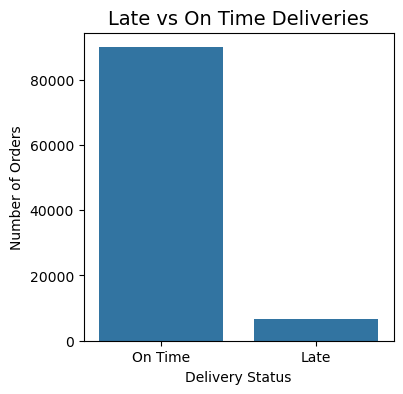

In [11]:
delivery_counts = delivery["delivery_status"].value_counts()

plt.figure(figsize=(4, 4))

sns.barplot(
    x=delivery_counts.index,
    y=delivery_counts.values
)

plt.title("Late vs On Time Deliveries", fontsize=14)
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")

plt.show()

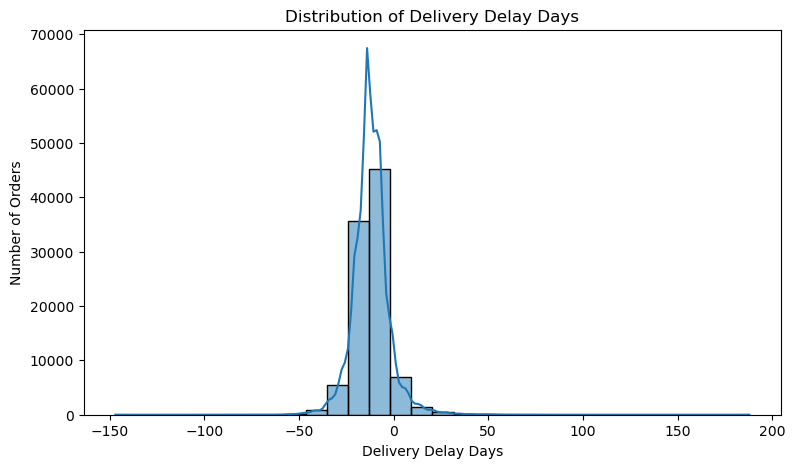

In [53]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=delivery,
    x="delivery_delay_days",
    bins=30,
    kde=True
)

plt.title("Distribution of Delivery Delay Days")
plt.xlabel("Delivery Delay Days")
plt.ylabel("Number of Orders")

plt.show()

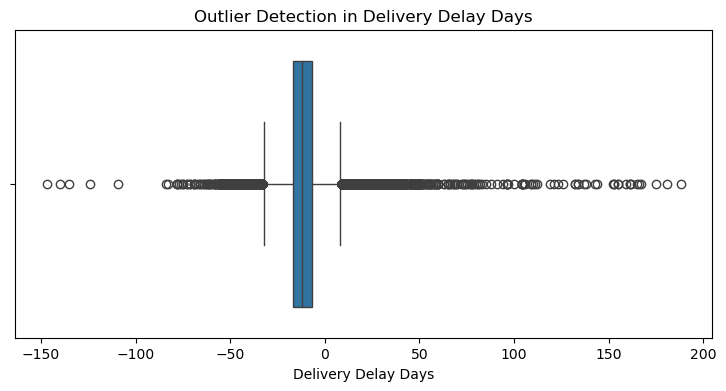

In [54]:
plt.figure(figsize=(9, 4))

sns.boxplot(
    data=delivery,
    x="delivery_delay_days"
)

plt.title("Outlier Detection in Delivery Delay Days")
plt.xlabel("Delivery Delay Days")

plt.show()

In [10]:
customers = pd.read_csv(
    r"C:\Users\acer\Downloads\olist_customers_dataset.csv.zip"
)

print(customers.shape)
print(customers.head())

(99441, 5)
                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   
3  b2b6027bc5c5109e529d4dc6358b12c3  259dac757896d24d7702b9acbbff3f3c   
4  4f2d8ab171c80ec8364f7c12e35b23ad  345ecd01c38d18a9036ed96c73b8d066   

   customer_zip_code_prefix          customer_city customer_state  
0                     14409                 franca             SP  
1                      9790  sao bernardo do campo             SP  
2                      1151              sao paulo             SP  
3                      8775        mogi das cruzes             SP  
4                     13056               campinas             SP  


In [11]:
delivery_state = delivery.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)
print(delivery_state.shape)
print(delivery_state[
    ["order_id", "customer_id", "customer_state"]
].head())

(96470, 11)
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  customer_state  
0             SP  
1             BA  
2             GO  
3             RN  
4             SP  


In [12]:
state_analysis = delivery_state.groupby(
    "customer_state"
).agg(
    total_orders=("order_id", "count"),
    late_orders=("delivery_status",
                 lambda x: (x == "Late").sum())
)

state_analysis["late_delivery_rate"] = (
    state_analysis["late_orders"]
    / state_analysis["total_orders"]
) * 100

state_analysis = state_analysis.sort_values(
    "late_delivery_rate",
    ascending=False
)

print(state_analysis.head(10).round(2))

                total_orders  late_orders  late_delivery_rate
customer_state                                               
AL                       397           85               21.41
MA                       717          125               17.43
SE                       335           51               15.22
PI                       476           66               13.87
CE                      1279          176               13.76
RR                        41            5               12.20
BA                      3256          396               12.16
RJ                     12350         1495               12.11
PA                       946          106               11.21
ES                      1995          214               10.73


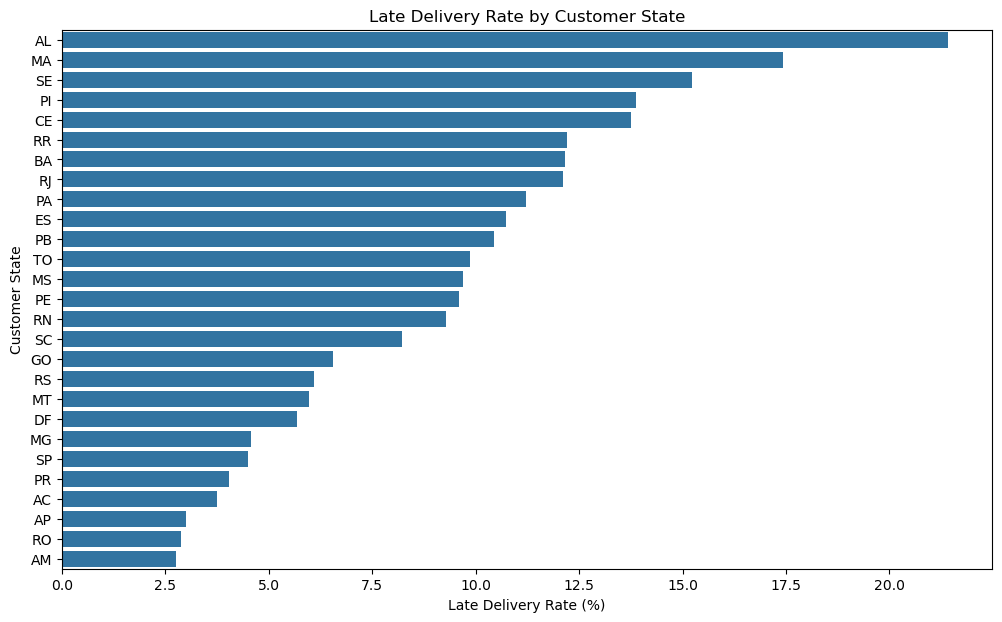

In [60]:
plt.figure(figsize=(12, 7))

state_sorted = state_analysis.sort_values(
    by="late_delivery_rate",
    ascending=False
)

sns.barplot(
    data=state_sorted,
    x="late_delivery_rate",
    y="customer_state"
)

plt.title("Late Delivery Rate by Customer State")
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Customer State")

plt.show()

In [13]:
items = pd.read_csv(
    r"C:\Users\acer\Downloads/olist_order_items_dataset.csv.zip"
)
print(items.shape)
print(items.head())

(112650, 7)
                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value  
0  2017-09-19 09:45:35   58.90          13.29  
1  2017-05-03 11:05:13  239.90          19.93  
2  2018-01-18 14:48:30  199.00          17.87  
3  2018-08-15 10:10:18   12.99  

In [14]:
seller_delivery = delivery[
    ["order_id", "delivery_status", "delivery_delay_days"]
].merge(
    items[["order_id", "seller_id"]],
    on="order_id",
    how="inner"
)

seller_delivery = seller_delivery.drop_duplicates(
    subset=["order_id", "seller_id"]
)

print(seller_delivery.head())
print("Unique order-seller pairs:", len(seller_delivery))

                           order_id delivery_status  delivery_delay_days  \
0  e481f51cbdc54678b7cc49136f2d6af7         On Time                   -8   
1  53cdb2fc8bc7dce0b6741e2150273451         On Time                   -6   
2  47770eb9100c2d0c44946d9cf07ec65d         On Time                  -18   
3  949d5b44dbf5de918fe9c16f97b45f8a         On Time                  -13   
4  ad21c59c0840e6cb83a9ceb5573f8159         On Time                  -10   

                          seller_id  
0  3504c0cb71d7fa48d967e0e4c94d59d9  
1  289cdb325fb7e7f891c38608bf9e0962  
2  4869f7a5dfa277a7dca6462dcf3b52b2  
3  66922902710d126a0e7d26b0e3805106  
4  2c9e548be18521d1c43cde1c582c6de8  
Unique order-seller pairs: 97811


In [15]:
seller_analysis = seller_delivery.groupby(
    "seller_id"
).agg(
    total_orders=("order_id", "count"),
    late_orders=(
        "delivery_status",
        lambda x: (x == "Late").sum()
    )
)

seller_analysis["late_delivery_rate"] = (
    seller_analysis["late_orders"]
    / seller_analysis["total_orders"]
) * 100

seller_analysis = seller_analysis[
    seller_analysis["total_orders"] >= 50
].sort_values(
    "late_delivery_rate",
    ascending=False
)

print(seller_analysis.head(10).round(2))

                                  total_orders  late_orders  \
seller_id                                                     
54965bbe3e4f07ae045b90b0b8541f52            73           22   
beadbee30901a7f61d031b6b686095ad            64           15   
a49928bcdf77c55c6d6e05e09a9b4ca5            96           21   
712e6ed8aa4aa1fa65dab41fed5737e4            77           16   
06a2c3af7b3aee5d69171b0e14f0ee87           389           74   
ea566164622c6b439516ab18062c42cd            50            9   
002100f778ceb8431b7a1020ff7ab48f            50            9   
cac4c8e7b1ca6252d8f20b2fc1a2e4af            74           13   
6039e27294dc75811c0d8a39069f52c0            63           11   
88460e8ebdecbfecb5f9601833981930           246           42   

                                  late_delivery_rate  
seller_id                                             
54965bbe3e4f07ae045b90b0b8541f52               30.14  
beadbee30901a7f61d031b6b686095ad               23.44  
a49928bcdf77c55c6d6e05e

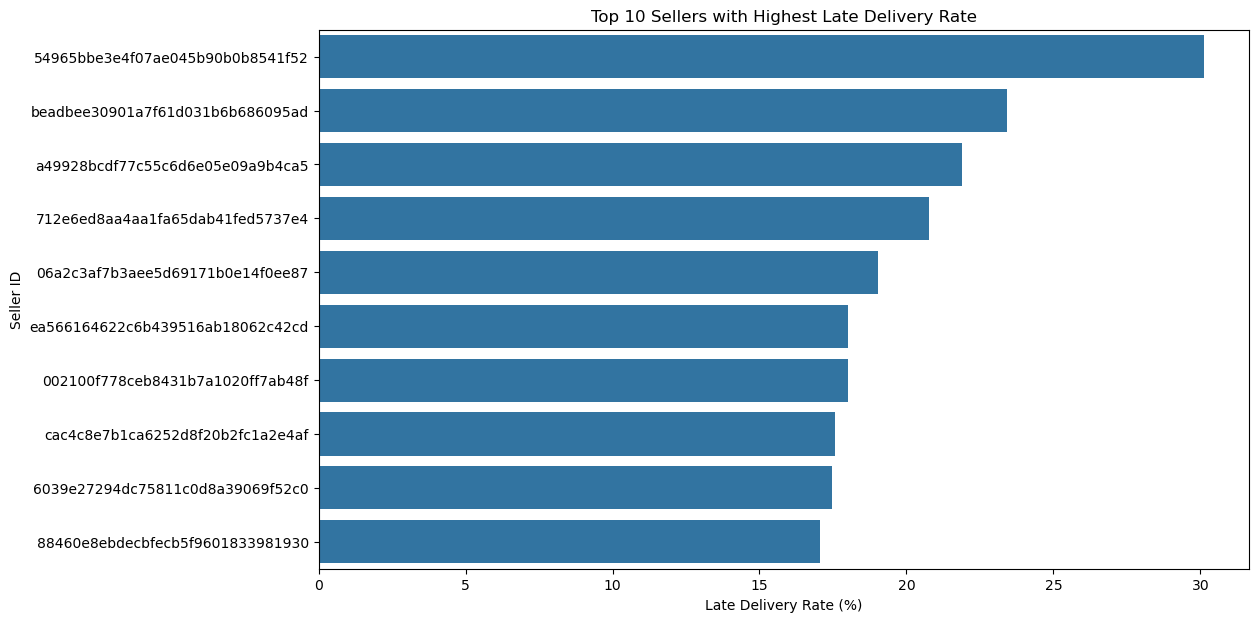

In [62]:
top_sellers = seller_analysis.sort_values(
    by="late_delivery_rate",
    ascending=False
).head(10)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_sellers,
    x="late_delivery_rate",
    y="seller_id"
)

plt.title("Top 10 Sellers with Highest Late Delivery Rate")
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Seller ID")

plt.show()

In [16]:
reviews = pd.read_csv(
    r"C:\Users\acer\Downloads\olist_order_reviews_dataset.csv.zip"
)

print(reviews.shape)
print(reviews.head())

(99224, 7)
                          review_id                          order_id  \
0  7bc2406110b926393aa56f80a40eba40  73fc7af87114b39712e6da79b0a377eb   
1  80e641a11e56f04c1ad469d5645fdfde  a548910a1c6147796b98fdf73dbeba33   
2  228ce5500dc1d8e020d8d1322874b6f0  f9e4b658b201a9f2ecdecbb34bed034b   
3  e64fb393e7b32834bb789ff8bb30750e  658677c97b385a9be170737859d3511b   
4  f7c4243c7fe1938f181bec41a392bdeb  8e6bfb81e283fa7e4f11123a3fb894f1   

   review_score review_comment_title  \
0             4                  NaN   
1             5                  NaN   
2             5                  NaN   
3             5                  NaN   
4             5                  NaN   

                              review_comment_message review_creation_date  \
0                                                NaN  2018-01-18 00:00:00   
1                                                NaN  2018-03-10 00:00:00   
2                                                NaN  2018-02-17 00:00:00   
3

In [17]:
delivery_reviews = delivery[
    ["order_id", "delivery_status", "delivery_delay_days"]
].merge(
    reviews[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

print(delivery_reviews.shape)
print(delivery_reviews.head())

(96353, 4)
                           order_id delivery_status  delivery_delay_days  \
0  e481f51cbdc54678b7cc49136f2d6af7         On Time                   -8   
1  53cdb2fc8bc7dce0b6741e2150273451         On Time                   -6   
2  47770eb9100c2d0c44946d9cf07ec65d         On Time                  -18   
3  949d5b44dbf5de918fe9c16f97b45f8a         On Time                  -13   
4  ad21c59c0840e6cb83a9ceb5573f8159         On Time                  -10   

   review_score  
0             4  
1             4  
2             5  
3             5  
4             5  


In [18]:
review_analysis = delivery_reviews.groupby(
    "delivery_status"
).agg(
    total_reviews=("review_score", "count"),
    average_review_score=("review_score", "mean")
)

print(review_analysis.round(2))

                 total_reviews  average_review_score
delivery_status                                     
Late                      6409                  2.27
On Time                  89944                  4.29


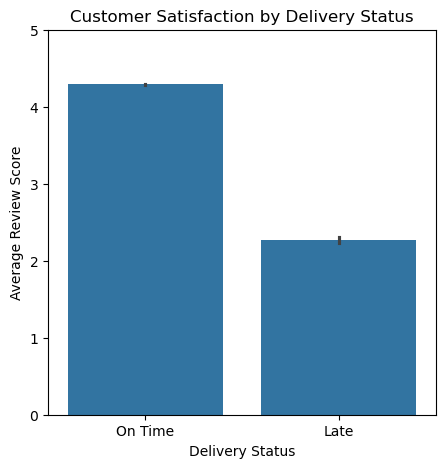

In [67]:
plt.figure(figsize=(5, 5))

sns.barplot(
    data=delivery_reviews,
    x="delivery_status",
    y="review_score",
    estimator="mean"
)

plt.title("Customer Satisfaction by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")

plt.ylim(0, 5)

plt.show()

In [19]:
delivery_reviews["low_review"] = (
    delivery_reviews["review_score"] <= 2
)

low_review_analysis = delivery_reviews.groupby(
    "delivery_status"
).agg(
    total_reviews=("review_score", "count"),
    low_reviews=("low_review", "sum")
)

low_review_analysis["low_review_percentage"] = (
    low_review_analysis["low_reviews"]
    / low_review_analysis["total_reviews"]
) * 100

print(low_review_analysis.round(2))

                 total_reviews  low_reviews  low_review_percentage
delivery_status                                                   
Late                      6409         4000                  62.41
On Time                  89944         8346                   9.28


In [20]:
customer_orders = Orders[
    Orders["order_status"] == "delivered"
].copy()

customer_orders = customer_orders.dropna(
    subset=[
        "customer_id",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

customer_orders = customer_orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print(customer_orders[
    ["customer_id", "customer_unique_id"]
].head())

print("Rows:", len(customer_orders))
print("Missing unique customer IDs:",
      customer_orders["customer_unique_id"].isna().sum())

                        customer_id                customer_unique_id
0  9ef432eb6251297304e76186b10a928d  7c396fd4830fd04220f754e42b4e5bff
1  b0830fb4747a6c6d20dea0b8c802d7ef  af07308b275d755c9edb36a90c618231
2  41ce2a54c0b03bf3443c3d931a367089  3a653a41f6f9fc3d2a113cf8398680e8
3  f88197465ea7920adcdbec7375364d82  7c142cf63193a1473d2e66489a9ae977
4  8ab97904e6daea8866dbdbc4fb7aad2c  72632f0f9dd73dfee390c9b22eb56dd6
Rows: 96470
Missing unique customer IDs: 0


In [26]:
first_orders = customer_orders.drop_duplicates(
    subset=["customer_id"],
    keep="first"
).copy()

print(first_orders[
    ["customer_id", "order_id", "delivery_status"]
].head())

                        customer_id                          order_id  \
0  9ef432eb6251297304e76186b10a928d  e481f51cbdc54678b7cc49136f2d6af7   
1  b0830fb4747a6c6d20dea0b8c802d7ef  53cdb2fc8bc7dce0b6741e2150273451   
2  41ce2a54c0b03bf3443c3d931a367089  47770eb9100c2d0c44946d9cf07ec65d   
3  f88197465ea7920adcdbec7375364d82  949d5b44dbf5de918fe9c16f97b45f8a   
4  8ab97904e6daea8866dbdbc4fb7aad2c  ad21c59c0840e6cb83a9ceb5573f8159   

  delivery_status  
0         On Time  
1         On Time  
2         On Time  
3         On Time  
4         On Time  


In [ ]:
order_counts = customer_orders.groupby(
    "customer_id"
).agg(
    delivered_order_count=("order_id", "nunique")
)

customer_analysis = first_orders[
    ["customer_id", "delivery_status"]
].merge(
    order_counts,
    on="customer_id",
    how="left"
)

customer_analysis["repeat_customer"] = (
    customer_analysis["delivered_order_count"] > 1
)

print(customer_analysis.head())

In [ ]:
repeat_analysis = customer_analysis.groupby(
    "delivery_status"
).agg(
    total_customers=("customer_id", "count"),
    repeat_customers=("repeat_customer", "sum")
)

repeat_analysis["repeat_purchase_rate"] = (
    repeat_analysis["repeat_customers"]
    / repeat_analysis["total_customers"]
) * 100

print(repeat_analysis.round(2))

In [49]:
customer_orders["delivery_delay_days"] = (
    customer_orders["order_delivered_customer_date"].dt.normalize()
    - customer_orders["order_estimated_delivery_date"].dt.normalize()
).dt.days

customer_orders["delivery_status"] = customer_orders[
    "delivery_delay_days"
].apply(
    lambda days: "Late" if days > 0 else "On Time"
)

In [50]:
customer_orders = customer_orders.sort_values(
    ["customer_unique_id", "order_purchase_timestamp"]
)

first_orders = customer_orders.drop_duplicates(
    subset=["customer_unique_id"],
    keep="first"
).copy()

print("Unique customers:", first_orders["customer_unique_id"].nunique())

Unique customers: 93350


In [31]:
order_counts = customer_orders.groupby(
    "customer_unique_id"
).agg(
    delivered_order_count=("order_id", "nunique")
)

customer_analysis = first_orders[
    ["customer_unique_id", "delivery_status"]
].merge(
    order_counts,
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

customer_analysis["repeat_customer"] = (
    customer_analysis["delivered_order_count"] > 1
)

In [32]:
repeat_analysis = customer_analysis.groupby(
    "delivery_status"
).agg(
    total_customers=("customer_unique_id", "nunique"),
    repeat_customers=("repeat_customer", "sum")
)

repeat_analysis["repeat_purchase_rate"] = (
    repeat_analysis["repeat_customers"]
    / repeat_analysis["total_customers"]
) * 100

print(repeat_analysis.round(2))

                 total_customers  repeat_customers  repeat_purchase_rate
delivery_status                                                         
Late                        6357               162                  2.55
On Time                    86993              2639                  3.03


In [74]:
delivery_state["purchase_month"] = pd.to_datetime(
    delivery_state["order_purchase_timestamp"]
).dt.month_name()

monthly_analysis = delivery_state.groupby("purchase_month").agg(
    total_orders=("order_id", "count"),
    late_orders=("delivery_status", lambda x: (x == "Late").sum())
)

monthly_analysis["late_delivery_rate"] = (
    monthly_analysis["late_orders"] /
    monthly_analysis["total_orders"] * 100
)

monthly_analysis

,total_orders,late_orders,late_delivery_rate
purchase_month,,,
April,9101,457,5.021426
August,10544,515,4.884294
December,5514,411,7.453754
February,8208,975,11.878655
January,7819,425,5.435478
July,10028,316,3.151177
June,9231,166,1.798288
March,9549,1444,15.122002
May,10294,549,5.333204


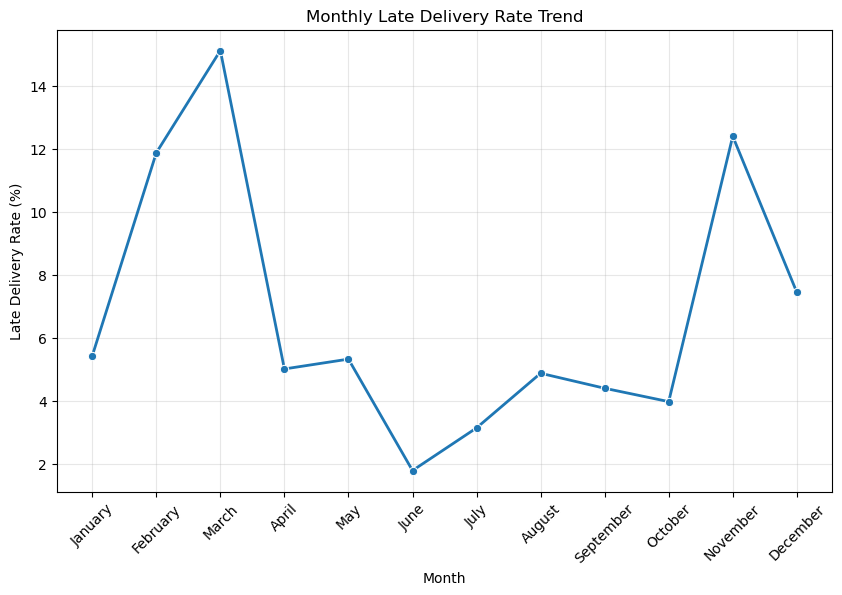

In [76]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_analysis = monthly_analysis.reindex(month_order)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=monthly_analysis,
    x=monthly_analysis.index,
    y="late_delivery_rate",
    marker="o",
    linewidth=2
)

plt.title("Monthly Late Delivery Rate Trend")
plt.xlabel("Month")
plt.ylabel("Late Delivery Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

In [33]:
print(review_analysis.round(2))
print(low_review_analysis.round(2))

                 total_reviews  average_review_score
delivery_status                                     
Late                      6409                  2.27
On Time                  89944                  4.29
                 total_reviews  low_reviews  low_review_percentage
delivery_status                                                   
Late                      6409         4000                  62.41
On Time                  89944         8346                   9.28


In [34]:
shipping_analysis = delivery.merge(
    items[["order_id", "freight_value"]],
    on="order_id",
    how="inner"
)

shipping_analysis["freight_group"] = pd.cut(
    shipping_analysis["freight_value"],
    bins=[-1, 10, 25, 50, float("inf")],
    labels=["Low", "Medium", "High", "Very High"]
)

freight_analysis = shipping_analysis.groupby(
    "freight_group", observed=True
).agg(
    total_records=("order_id", "count"),
    late_records=(
        "delivery_status",
        lambda x: (x == "Late").sum()
    )
)

freight_analysis["late_rate"] = (
    freight_analysis["late_records"]
    / freight_analysis["total_records"] * 100
)

print(freight_analysis.round(2))

               total_records  late_records  late_rate
freight_group                                        
Low                    15561           647       4.16
Medium                 75757          4990       6.59
High                   14412          1201       8.33
Very High               4459           426       9.55


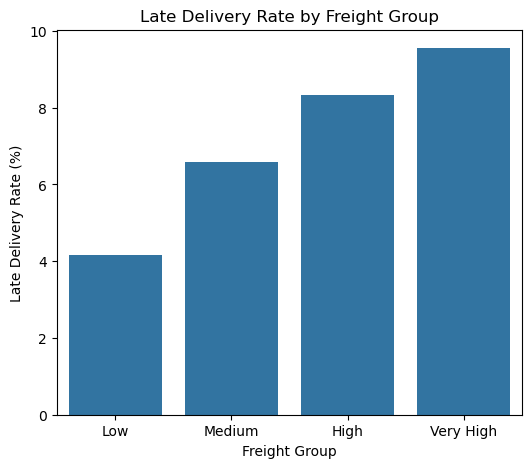

In [70]:
plt.figure(figsize=(6, 5))

sns.barplot(
    data=freight_analysis,
    x=freight_analysis.index,
    y="late_rate"
)

plt.title("Late Delivery Rate by Freight Group")
plt.xlabel("Freight Group")
plt.ylabel("Late Delivery Rate (%)")

plt.show()

In [35]:
import pandas as pd

payments = pd.read_csv(
    r"C:\Users\acer\Downloads\olist_order_payments_dataset.csv.zip"
)

print(payments.head())
print(payments.shape)

                           order_id  payment_sequential payment_type  \
0  b81ef226f3fe1789b1e8b2acac839d17                   1  credit_card   
1  a9810da82917af2d9aefd1278f1dcfa0                   1  credit_card   
2  25e8ea4e93396b6fa0d3dd708e76c1bd                   1  credit_card   
3  ba78997921bbcdc1373bb41e913ab953                   1  credit_card   
4  42fdf880ba16b47b59251dd489d4441a                   1  credit_card   

   payment_installments  payment_value  
0                     8          99.33  
1                     1          24.39  
2                     1          65.71  
3                     8         107.78  
4                     2         128.45  
(103886, 5)


In [36]:
payment_analysis = payments.groupby(
    "payment_type"
).agg(
    total_payments=("payment_value", "count"),
    average_payment=("payment_value", "mean"),
    total_payment_value=("payment_value", "sum")
)

payment_analysis = payment_analysis.sort_values(
    "total_payment_value", ascending=False
)

print(payment_analysis.round(2))

              total_payments  average_payment  total_payment_value
payment_type                                                      
credit_card            76795           163.32          12542084.19
boleto                 19784           145.03           2869361.27
voucher                 5775            65.70            379436.87
debit_card              1529           142.57            217989.79
not_defined                3             0.00                 0.00


In [37]:
seller_delivery = delivery[
    ["order_id", "delivery_status"]
].merge(
    items[["order_id", "seller_id"]].drop_duplicates(),
    on="order_id",
    how="inner"
)

seller_analysis = seller_delivery.groupby("seller_id").agg(
    total_orders=("order_id", "nunique"),
    late_orders=(
        "delivery_status",
        lambda x: (x == "Late").sum()
    )
)

seller_analysis["late_delivery_rate"] = (
    seller_analysis["late_orders"]
    / seller_analysis["total_orders"] * 100
)

seller_analysis = seller_analysis[
    seller_analysis["total_orders"] >= 50
].sort_values("late_delivery_rate", ascending=False)

print(seller_analysis.head(10).round(2))

                                  total_orders  late_orders  \
seller_id                                                     
54965bbe3e4f07ae045b90b0b8541f52            73           22   
beadbee30901a7f61d031b6b686095ad            64           15   
a49928bcdf77c55c6d6e05e09a9b4ca5            96           21   
712e6ed8aa4aa1fa65dab41fed5737e4            77           16   
06a2c3af7b3aee5d69171b0e14f0ee87           389           74   
ea566164622c6b439516ab18062c42cd            50            9   
002100f778ceb8431b7a1020ff7ab48f            50            9   
cac4c8e7b1ca6252d8f20b2fc1a2e4af            74           13   
6039e27294dc75811c0d8a39069f52c0            63           11   
88460e8ebdecbfecb5f9601833981930           246           42   

                                  late_delivery_rate  
seller_id                                             
54965bbe3e4f07ae045b90b0b8541f52               30.14  
beadbee30901a7f61d031b6b686095ad               23.44  
a49928bcdf77c55c6d6e05e

In [38]:
base_orders = delivery[
    [
        "order_id",
        "customer_id",
        "order_purchase_timestamp",
        "delivery_delay_days",
        "delivery_status"
    ]
].copy()
base_orders = base_orders.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)
print(base_orders.head())
print("Total rows:", len(base_orders))
print("Unique orders:", base_orders["order_id"].nunique())
print("Missing customer states:", base_orders["customer_state"].isna().sum())

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_purchase_timestamp  delivery_delay_days delivery_status customer_state  
0      2017-10-02 10:56:33                   -8         On Time             SP  
1      2018-07-24 20:41:37                   -6         On Time             BA  
2      2018-08-08 08:38:49                  -18         On Time             GO  
3      2017-11-18 19:28:06                  -13         On Time             RN  
4      2018-02-13 21:18:39                  -10         On Time             SP  
Total rows: 96470
Unique orders: 96470
Missing customer states: 0


In [41]:
reviews_clean = reviews[
    ["order_id", "review_score"]
].copy()

reviews_clean["review_score"] = pd.to_numeric(
    reviews_clean["review_score"],
    errors="coerce"
)

reviews_by_order = reviews_clean.groupby(
    "order_id", as_index=False
).agg(
    review_score=("review_score", "mean")
)
base_orders = base_orders.merge(
    reviews_by_order,
    on="order_id",
    how="left",
    validate="one_to_one"
)
print(base_orders[
    ["order_id", "delivery_status", "customer_state", "review_score"]
].head(10))

print("Total rows:", len(base_orders))
print("Unique orders:", base_orders["order_id"].nunique())
print("Missing review scores:", base_orders["review_score"].isna().sum())

                           order_id delivery_status customer_state  \
0  e481f51cbdc54678b7cc49136f2d6af7         On Time             SP   
1  53cdb2fc8bc7dce0b6741e2150273451         On Time             BA   
2  47770eb9100c2d0c44946d9cf07ec65d         On Time             GO   
3  949d5b44dbf5de918fe9c16f97b45f8a         On Time             RN   
4  ad21c59c0840e6cb83a9ceb5573f8159         On Time             SP   
5  a4591c265e18cb1dcee52889e2d8acc3         On Time             PR   
6  6514b8ad8028c9f2cc2374ded245783f         On Time             RJ   
7  76c6e866289321a7c93b82b54852dc33         On Time             RS   
8  e69bfb5eb88e0ed6a785585b27e16dbf         On Time             SP   
9  e6ce16cb79ec1d90b1da9085a6118aeb         On Time             RJ   

   review_score  
0           4.0  
1           4.0  
2           5.0  
3           5.0  
4           5.0  
5           4.0  
6           5.0  
7           1.0  
8           5.0  
9           1.0  
Total rows: 96470
Unique orders

In [44]:
payments_clean = payments[
    ["order_id", "payment_value"]
].copy()
payments_by_order = payments_clean.groupby(
    "order_id",
    as_index=False
).agg(
    total_payment_value=("payment_value", "sum")
)
if "total_payment_value" in base_orders.columns:
    base_orders = base_orders.drop(
        columns=["total_payment_value"]
    )
print("Duplicate orders:", base_orders["order_id"].duplicated().sum())
base_orders = base_orders.merge(
    payments_by_order,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print(base_orders[
    ["order_id", "review_score", "total_payment_value"]
].head(10))

print("Total rows:", len(base_orders))
print(
    "Unique orders:",
    base_orders["order_id"].nunique()
)
print(
    "Missing payment values:",
    base_orders["total_payment_value"].isna().sum()
)

Duplicate orders: 0
                           order_id  review_score  total_payment_value
0  e481f51cbdc54678b7cc49136f2d6af7           4.0                38.71
1  53cdb2fc8bc7dce0b6741e2150273451           4.0               141.46
2  47770eb9100c2d0c44946d9cf07ec65d           5.0               179.12
3  949d5b44dbf5de918fe9c16f97b45f8a           5.0                72.20
4  ad21c59c0840e6cb83a9ceb5573f8159           5.0                28.62
5  a4591c265e18cb1dcee52889e2d8acc3           4.0               175.26
6  6514b8ad8028c9f2cc2374ded245783f           5.0                75.16
7  76c6e866289321a7c93b82b54852dc33           1.0                35.95
8  e69bfb5eb88e0ed6a785585b27e16dbf           5.0               169.76
9  e6ce16cb79ec1d90b1da9085a6118aeb           1.0               259.06
Total rows: 96470
Unique orders: 96470
Missing payment values: 1


In [45]:
items_clean = items[
    ["order_id", "freight_value"]
].copy()
freight_by_order = items_clean.groupby(
    "order_id", as_index=False
).agg(
    total_freight_value=("freight_value", "sum")
)
base_orders = base_orders.merge(
    freight_by_order,
    on="order_id",
    how="left",
    validate="one_to_one"
)
print(base_orders[
    ["order_id", "total_payment_value", "total_freight_value"]
].head(10))

print("Total rows:", len(base_orders))
print("Unique orders:", base_orders["order_id"].nunique())
print(
    "Missing freight values:",
    base_orders["total_freight_value"].isna().sum()
)

                           order_id  total_payment_value  total_freight_value
0  e481f51cbdc54678b7cc49136f2d6af7                38.71                 8.72
1  53cdb2fc8bc7dce0b6741e2150273451               141.46                22.76
2  47770eb9100c2d0c44946d9cf07ec65d               179.12                19.22
3  949d5b44dbf5de918fe9c16f97b45f8a                72.20                27.20
4  ad21c59c0840e6cb83a9ceb5573f8159                28.62                 8.72
5  a4591c265e18cb1dcee52889e2d8acc3               175.26                27.36
6  6514b8ad8028c9f2cc2374ded245783f                75.16                15.17
7  76c6e866289321a7c93b82b54852dc33                35.95                16.05
8  e69bfb5eb88e0ed6a785585b27e16dbf               169.76                19.77
9  e6ce16cb79ec1d90b1da9085a6118aeb               259.06                61.06
Total rows: 96470
Unique orders: 96470
Missing freight values: 0


In [46]:
print("Dataset shape:", base_orders.shape)
print("\nColumn names:")
print(base_orders.columns.tolist())

print(
    "\nDuplicate order IDs:",
    base_orders["order_id"].duplicated().sum()
)

print("\nMissing values:")
print(base_orders.isna().sum())

print("\nDelivery status:")
print(base_orders["delivery_status"].value_counts())

print("\nNumeric summary:")
print(
    base_orders[
        [
            "delivery_delay_days",
            "review_score",
            "total_payment_value",
            "total_freight_value"
        ]
    ].describe().round(2)
)

Dataset shape: (96470, 11)

Column names:
['order_id', 'customer_id', 'order_purchase_timestamp', 'delivery_delay_days', 'delivery_status', 'customer_state', 'total_payment_value_x', 'review_score', 'total_payment_value_y', 'total_payment_value', 'total_freight_value']

Duplicate order IDs: 0

Missing values:
order_id                      0
customer_id                   0
order_purchase_timestamp      0
delivery_delay_days           0
delivery_status               0
customer_state                0
total_payment_value_x         1
review_score                646
total_payment_value_y         1
total_payment_value           1
total_freight_value           0
dtype: int64

Delivery status:
delivery_status
On Time    89936
Late        6534
Name: count, dtype: int64

Numeric summary:
       delivery_delay_days  review_score  total_payment_value  \
count             96470.00      95824.00             96469.00   
mean                -11.88          4.16               159.86   
std              

In [47]:
print(
    base_orders.loc[
        base_orders["total_payment_value"].isna(),
        ["order_id", "customer_id", "delivery_status"]
    ]
)

                               order_id                       customer_id  \
29809  bfbd0f9bdef84302105ad712db648a6c  86dc2ffce2dfff336de2f386a786e574   

      delivery_status  
29809            Late  


In [ ]:
# Business Recommendations

1. Improve logistics planning in states with higher delivery delays.
2. Monitor sellers with consistently high late delivery rates.
3. Improve delivery scheduling during months with higher delay rates.
4. Monitor customer satisfaction and resolve delivery-related complaints.
5. Investigate the relationship between freight value and delivery performance.

# Project Conclusion

The Olist E-Commerce Delivery Delay Analysis was performed using Python libraries including Pandas, NumPy, Matplotlib and Seaborn.

The analysis helped identify late delivery patterns across different months, customer states, sellers and freight groups.

It also revealed that late deliveries are associated with lower customer review scores.

These findings can help businesses improve logistics planning, monitor seller performance and increase customer satisfaction.

**Project Status:** Python Data Cleaning, Exploratory Data Analysis and Visualization Completed.

In [80]:
import os

output_path = os.path.join(
    os.path.expanduser("~"),
    "Downloads",
    "olist_powerbi_analysis.csv"
)

base_orders.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset exported successfully!")
print("Saved location:", output_path)

Dataset exported successfully!
Saved location: C:\Users\acer\Downloads\olist_powerbi_analysis.csv
